# Neural adaptation and baseline comparisons

Md Forhadul Islam, London

This is my independent Dota 2 adaptation of the approach of Fazilat Hojaji,
Robert E. McIlroy, Antoine Dupuy, Gianpaolo Pedroni, Adam J. Toth and Mark J. Campbell.
Their original League of Legends paper is https://doi.org/10.1016/j.chbr.2025.100718.
It is not an exact reproduction of their numerical results. The Betty dataset is
published by wolframko using Valve replays and STRATZ data. Sources, licences and
the literature tracker are recorded in the project documentation.

I explain each step before the code and interpret the output afterwards. All
displayed experimental results come from saved calculations. Reading them does
not train a new model or choose an approach using the final test outcomes.


## Find the saved study

A path tells Python where a file lives. JSON stores labelled evidence. A DataFrame is a table with named columns. This setup reads existing results; it cannot change trained weights or the test partition.

In [1]:
from pathlib import Path  # Represent folders consistently on Windows and other systems.
import sys  # Make the shared project modules available to this notebook.
import json  # Read saved evidence with its original field names.
import pandas as pd  # Display numerical records as labelled tables.
from IPython.display import display, Image, Markdown  # Show readable tables, figures and notes.
ROOT = Path.cwd().resolve()  # Begin from the notebook execution folder.
if ROOT.name == "notebooks":  # Jupyter normally starts within the notebook folder.
    ROOT = ROOT.parent  # Move up once to reach the shared project directory.
assert (ROOT / "src").is_dir(), "Open this notebook from the project or notebooks folder."
sys.path.insert(0, str(ROOT / "src"))  # Import the same scientific code used by terminal runs.
def evidence(filename):  # Keep evidence loading consistent across the notebook.
    return json.loads((ROOT / "outputs/results" / filename).read_text(encoding="utf-8"))  # Decode one saved result.
summary = evidence("D_summary.json")  # Read the completed study without recomputing final predictions.


## How do the four models differ?

Logistic regression learns a weighted sum of features and converts it into a probability. A random forest averages decision trees. XGBoost adds trees that correct earlier errors. The neural network learns two layers of nonlinear combinations. Scaling is fitted on training data for logistic regression and the neural network. Validation controls the neural checkpoint; it never uses final test outcomes.

In [2]:
display(pd.Series(summary["protocol"]["model_settings"], name="Frozen settings"))  # Show actual hyperparameters, not retrospectively selected ones.
print("Seeds:", summary["protocol"]["seeds"])  # Seeds make stochastic training repeatable.
print("Source implementation:", ROOT / "src/dota_models.py")  # Direct readers to the fully commented shared model code.

logistic                                 {'C': 1, 'max_iter': 2000}
random_forest     {'trees': 300, 'max_depth': 8, 'min_samples_le...
xgboost           {'trees': 400, 'max_depth': 3, 'learning_rate'...
neural_network    {'hidden': [64, 64], 'dropout': 0.5, 'optimize...
Name: Frozen settings, dtype: object

Seeds: [0, 1, 2]
Source implementation: C:\Users\Rey\Documents\Applications\Ireland\University of Limerick\Dr Fazilat Hojaji\Sports_KPI_Self_Study\src\dota_models.py


The neural architecture follows the original paper's two hidden layers, with adaptations for binary team differences and time observable Dota inputs. These are fixed reference settings, not an exhaustive hyperparameter search. Repeating deterministic logistic regression produces effectively zero seed spread.

## Where are the actual fitting results?

The saved development records come from fitting on training matches and measuring validation predictions. Each fitted model was cached. Training can be deliberately repeated with the development command in the README; this teaching notebook does not overwrite the frozen experiment.

,model,seed,matches,auc,training_seconds
24,logistic,0,1290,0.798024,0.004713
26,logistic,1,1290,0.798024,0.004795
28,logistic,2,1290,0.798024,0.004344
30,random_forest,0,1290,0.792404,0.356262
32,random_forest,1,1290,0.793004,0.348577
34,random_forest,2,1290,0.791790,0.355171
36,xgboost,0,1290,0.786757,0.559972
38,xgboost,1,1290,0.789339,0.435688
40,xgboost,2,1290,0.786447,0.402119
42,neural_network,0,1290,0.790982,0.560429


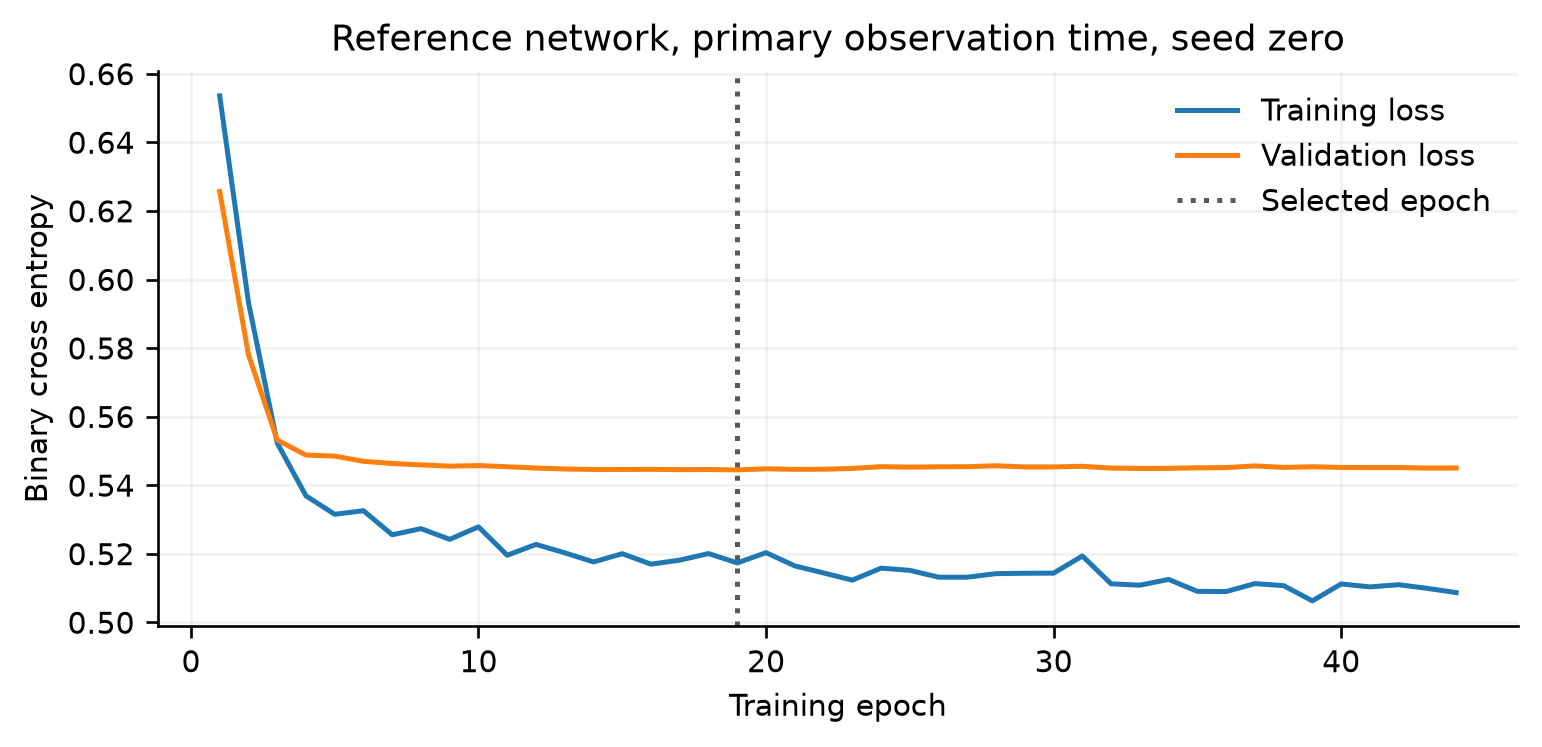

In [3]:
development = pd.DataFrame(evidence("D_development_metrics.json")["records"])  # Read actual per seed fits and validation measurements.
display(development.loc[(development.horizon_seconds == 1200) & (development.probability == "raw"), ["model", "seed", "matches", "auc", "training_seconds"]])  # Keep the training evidence separate from final results.
display(Image(filename=str(ROOT / "outputs/figures/D_learning_curve.png")))  # Display the saved neural development loss curve.

An epoch is one pass through the training data. Early stopping restores the best validation checkpoint rather than the last epoch. The curve describes a particular fitted run; it does not establish that the neural model is universally optimal.

## What do the metrics mean?

ROC AUC measures whether winners receive higher scores than losers across possible thresholds. Accuracy uses a probability threshold of 0.5. Brier score is the mean squared error of predicted probabilities. Log loss penalises confident mistakes. Higher AUC and accuracy are better; lower Brier score and log loss are better. Seed standard deviation describes training variation, not a confidence interval over new datasets.

,model,matches,auc_mean,auc_sd,accuracy_mean,brier_mean,log_loss_mean
8,logistic,1729,0.821289,0.000000,0.736842,0.172629,0.510833
10,neural_network,1729,0.814927,0.001977,0.736071,0.175458,0.517282
12,random_forest,1729,0.818904,0.001035,0.735685,0.174145,0.513546
14,xgboost,1729,0.813752,0.000372,0.731444,0.175974,0.517088


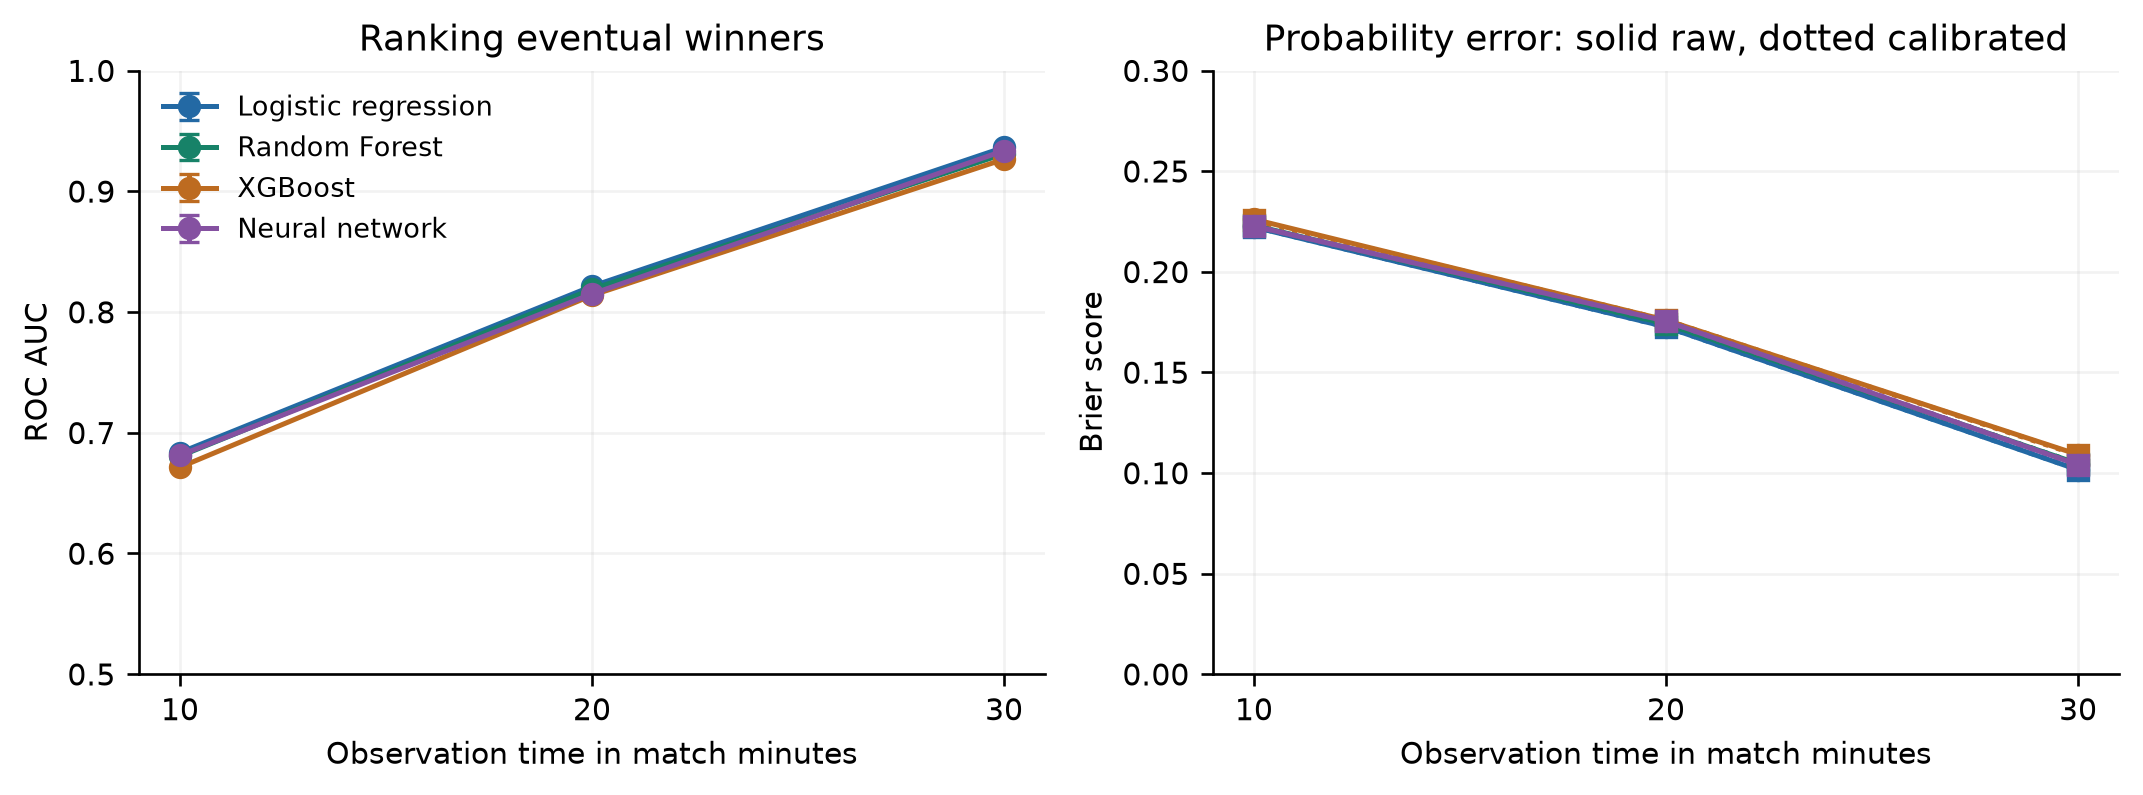

In [4]:
test = pd.DataFrame(summary["test_table"])  # Use the completed, saved final evaluation.
primary = test.loc[(test.horizon_seconds == 1200) & (test.probability == "raw")]  # Display the prespecified primary time and raw probabilities.
display(primary[["model", "matches", "auc_mean", "auc_sd", "accuracy_mean", "brier_mean", "log_loss_mean"]].round(6))  # Show all four models on the same eligible matches.
display(Image(filename=str(ROOT / "outputs/figures/D_performance.png")))  # Compare the three time horizons without refitting.

Logistic regression has a small advantage over the adapted neural model at the primary horizon in this dataset. This does not refute the original LoL findings or establish the best possible Dota model. Later time points have different eligible match populations.

## Is the difference larger than match sample uncertainty?

A paired bootstrap samples whole matches with replacement and measures both models on the same sampled games. The day block version samples whole UTC days, keeping same day games together. These are conditional intervals for the fitted predictions; they do not represent every source of uncertainty.

In [5]:
display(pd.DataFrame(summary["primary_paired_comparison"]["match"]))  # Show lower and upper interval endpoints for logistic minus neural.
display(pd.DataFrame(summary["primary_paired_comparison"]["utc_day_block"]))  # Check sensitivity to same day dependence.
display(pd.Series(summary["primary_paired_comparison"]["observed_logistic_minus_neural"]))  # Distinguish seed averaged predictions from the mean of seed metrics.
display(pd.DataFrame(summary["common_cohort_neural"]))  # Hold match membership fixed when comparing neural prediction times.

,auc,accuracy,brier,log_loss
0,0.002317,-0.008676,-0.004128,-0.009708
1,0.009242,0.011567,-0.000876,-0.001845


,auc,accuracy,brier,log_loss
0,0.001614,-0.008533,-0.004234,-0.009652
1,0.009833,0.011029,-0.000872,-0.001425


auc         0.005747
accuracy    0.001157
brier      -0.002515
log_loss   -0.005631
dtype: float64

,horizon_seconds,matches,auc,accuracy,brier,log_loss
0,600,664,0.623074,0.599398,0.238331,0.669537
1,1200,664,0.727763,0.656627,0.210880,0.604890
2,1800,664,0.935614,0.852410,0.102945,0.330038


The AUC intervals favour logistic regression for this fixed comparison. The accuracy interval includes zero. AUC of averaged predictions need not equal the average of per seed AUC values. The common horizon cohort controls one selection difference, but describes games with observations at every horizon rather than all games.

## Read the shared implementation line by line

The source below is the actual function used by the pipeline, including comments explaining what each operation does and why. `inspect` reads Python source; it does not call the function or refit a model. A function is a named sequence of reusable steps; a class groups a model's state and prediction methods. Read the comments alongside the preceding explanation, then open the source file to explore further. The frozen result record retains the original implementation fingerprints; later documentation changes do not replace that historical record.

In [6]:
import inspect  # Read implementation text without running a scientific experiment.
from IPython.display import Code  # Render Python source with readable syntax highlighting.
import dota_models  # Access the same shared module used by the terminal pipeline.
display(Code(inspect.getsource(dota_models.NeuralPredictor), language='python'))  # Show the commented implementation without calling it.
display(Code(inspect.getsource(dota_models.fit_model), language='python'))  # Show the commented implementation without calling it.

class NeuralPredictor:
    """A small two hidden layer network with training only standardisation.

    Inputs are numeric team differences. Outputs are Radiant win probabilities.
    The validation period chooses an epoch; calibration and test remain separate.
    """
    def __init__(self, seed=0):
        self.seed = seed  # Remember the training seed in the saved estimator.
        self.device = "cuda"  # Require the requested GPU instead of quietly falling back.

    def fit(self, X, y, X_validation, y_validation):
        seed_everything(self.seed)  # Make this particular training run reproducible.
        assert torch.cuda.is_available(), "CUDA is required for this study's neural runs."  # Report a genuine GPU failure clearly.
        torch.set_num_threads(4)  # Avoid excessive CPU thread overhead for a small dataset.
        self.scaler = StandardScaler().fit(X)  # Estimate scaling from training features only.
        x = torch.as_tensor(self.scaler.transform(X), dtype=torch.float32, device=self.device)  # Move the scaled training matrix to GPU memory.
        target = torch.as_tensor(np.asarray(y).copy(), dtype=torch.float32, device=self.device).reshape(-1, 1)  # Give binary labels a writable buffer and the same shape as network logits.
        xv = torch.as_tensor(self.scaler.transform(X_validation), dtype=torch.float32, device=self.device)  # Apply existing scaling to validation features.
        yv = torch.as_tensor(np.asarray(y_validation).copy(), dtype=torch.float32, device=self.device).reshape(-1, 1)  # Keep validation labels in a writable buffer separate from gradient updates.
        self.network = torch.nn.Sequential(torch.nn.Linear(x.shape[1], 64), torch.nn.ReLU(), torch.nn.Dropout(.5), torch.nn.Linear(64, 64), torch.nn.ReLU(), torch.nn.Dropout(.5), torch.nn.Linear(64, 1)).to(self.device)  # Use a documented architecture inspired by the original paper.
        optimizer = torch.optim.Adam(self.network.parameters(), lr=.001, weight_decay=1e-5)  # Use fixed settings rather than searching on test outcomes.
        loss_function = torch.nn.BCEWithLogitsLoss()  # Combine sigmoid and binary loss in a numerically stable form.
        best_loss, stale = float("inf"), 0  # Track improvements for early stopping.
        self.history = []  # Save learning curves instead of reporting only a final score.
        for epoch in range(200):  # Cap training at the prespecified number of passes.
            self.network.train()  # Enable dropout during training.
            order = torch.randperm(len(x), device=self.device)  # Shuffle training examples using the fixed random seed.
            total = 0.0  # Accumulate a sample weighted training loss.
            for batch in order.split(512):  # Keep small batches without repeatedly transferring data from the CPU.
                optimizer.zero_grad(set_to_none=True)  # Clear gradients from the previous update.
                loss = loss_function(self.network(x[batch]), target[batch])  # Compare predictions with training labels.
                loss.backward()  # Calculate how each weight affects the loss.
                optimizer.step()  # Move weights in a direction that reduces training loss.
                total += float(loss.detach()) * len(batch)  # Record loss without retaining the computation graph.
            self.network.eval()  # Disable dropout for comparable validation measurements.
            with torch.no_grad():  # Validation must not change the weights.
                validation_loss = float(loss_function(self.network(xv), yv))  # Use validation only to choose when to stop.
            self.history.append({"epoch": epoch + 1, "training_loss": total / len(x), "validation_loss": validation_loss})  # Preserve the observed curve.
            if validation_loss < best_loss - 1e-5:  # Require a small genuine improvement to reset patience.
                best_loss, stale = validation_loss, 0  # Update the best score and clear the no improvement count.
        

def fit_model(name, X, y, X_validation, y_validation, seed):
    """Fit one fixed model and return it with elapsed training seconds."""
    started = time.perf_counter()  # Start timing immediately before model construction and fitting.
    if name == "logistic":  # A linear decision rule is a useful simple comparison.
        model = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000, random_state=seed))  # Scale using training data within the pipeline.
    elif name == "random_forest":  # Trees can model nonlinear relationships without standardisation.
        model = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, max_features="sqrt", n_jobs=4, random_state=seed)  # Use fixed complexity and controlled parallelism.
    elif name == "xgboost":  # Boosting adds trees sequentially to reduce remaining error.
        model = XGBClassifier(n_estimators=400, max_depth=3, learning_rate=.05, subsample=.8, colsample_bytree=.8, reg_lambda=1, tree_method="hist", device="cuda", n_jobs=4, random_state=seed, eval_metric="logloss")  # Request GPU histogram training explicitly.
    elif name == "neural_network":  # The adapted neural model uses validation for checkpoint selection.
        model = NeuralPredictor(seed).fit(X, y, X_validation, y_validation)  # Train on GPU and retain the best validation epoch.
        torch.cuda.synchronize()  # Ensure timing includes completed CUDA operations.
        return model, time.perf_counter() - started  # Return a fitted model and observed elapsed time.
    else:  # A misspelled model name must not select an arbitrary fallback.
        raise ValueError(name)  # Stop with the unexpected value visible.
    model.fit(X, y)  # Fit the selected classical estimator using training data only.
    if name == "xgboost":  # GPU work can finish asynchronously.
        torch.cuda.synchronize()  # Wait before ending the timing interval.
    return model, time.perf_counter() - started  # Report the estimator and its actual training time.